**Bài 1: Vẽ dao động tần số của hàm sin và cos**

<ipython-input-12-58c24f607c13>:12: MatplotlibDeprecationWarning: Passing the NFFT parameter of csd() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.csd(s1, s2**2, 128, 1./dt)


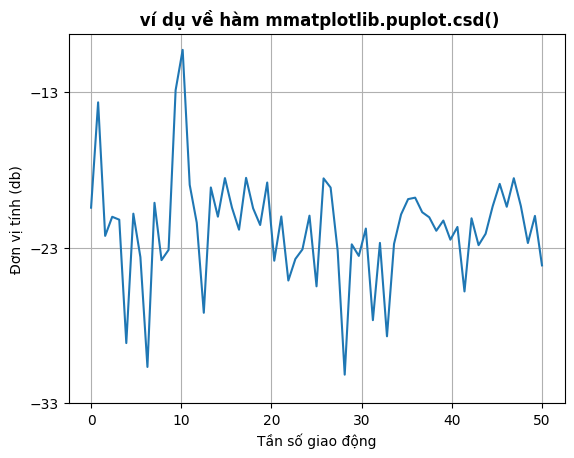

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.01
t = np.arange(0, 30, dt)
nse1 = np.random.randn(len(t))
nse2 = np.random.randn(len(t))

s1 = 1.5 * np.sin(2 *np.pi * 10 * t) + nse1
s2 = np.cos(np.pi * t) + nse2

plt.csd(s1, s2**2, 128, 1./dt)
plt.xlabel('Tần số giao động')
plt.ylabel('Đơn vị tính (db)')

plt.title(' ví dụ về hàm mmatplotlib.puplot.csd()',fontweight ="bold")
plt.show()


**Bài 2: Thực hiện thêm subplot**

<ipython-input-2-212f52051f33>:18: MatplotlibDeprecationWarning: Passing the NFFT parameter of psd() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.psd(s, 512, 1 / dt)


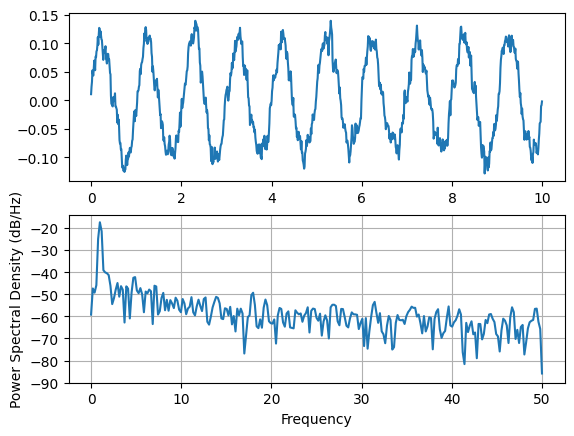

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(19680801)

dt = 0.01
t = np.arange(0, 10, dt)
nse1 = np.random.randn(len(t))
r = np.exp(-t / 0.05)

cnse = np.convolve(nse1, r) * dt
cnse = cnse[:len(t)]
s = 0.1 * np.sin(2 * np.pi * t) + cnse

plt.subplot(211)
plt.plot(t, s)
plt.subplot(212)
plt.psd(s, 512, 1 / dt)
plt.show()

**Bài 3: Thư viện scipy.signal:**

* Trước khi đi vào tính toán PSD thực tế, chúng ta cần tạo một số dữ liệu thử
nghiệm. Sử dụng hai sóng hình sin ở tần số 10Hz và 60Hz. Gói phân tích tín hiệu đi tới Scipy có triển khai tính toán các biểu đồ chu kỳ có sẵn scipy.signal.periodogram. Sử dụng chúng có thể dễ dàng tính toán mật độ phổ công suất.

* Sử dụng Scipy rất đơn giản, tất cả những gì chúng ta cần cung cấp cho phương
pháp biểu đồ chu kỳ là dữ liệu tín hiệu thực tế và tần số lấy mẫu.

* Những gì thu được từ phương pháp này là các thành phần tần số và mật độ công
suất tương ứng.

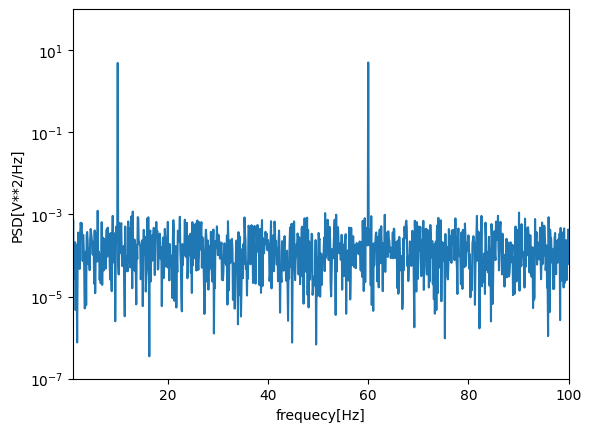

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal

fs = 1000.0
F1 = 10
F2 = 60
T = 10
N0 = -10
t = np.r_[ 0:T:(1/fs)]

signal = np.sin(2 * np.pi * F1 * t) + np.sin(2 * np.pi * F2 * t)
signal += np.random.randn(len(signal))*10**(N0/20.0)

(f,s) = scipy.signal.periodogram(signal, fs, scaling='density')
plt.semilogy(f,s)
plt.ylim([1e-7, 1e2])
plt.xlim([1, 100])
plt.xlabel('frequecy[Hz]')
plt.ylabel('PSD[V**2/Hz]')
plt.show()

**Bài 4: Triển khai Naive Python:**

* Tính toán PSD cho tần số [0,…100]

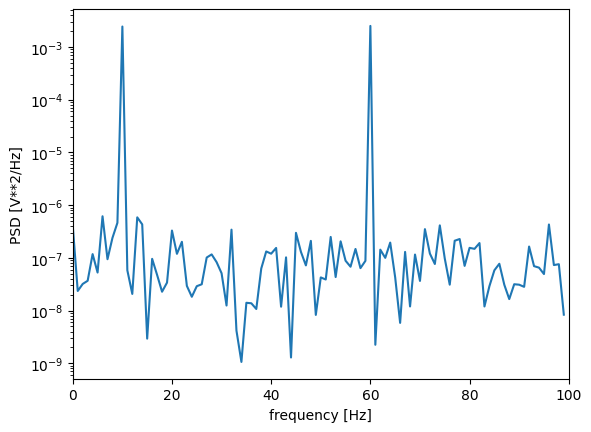

In [13]:
import numpy as np

def Sxx(f, signal, Fs):
    t = 1/Fs
    T = len(signal)

    s = np.sum([signal[i] * np.exp(-1j*2*np.pi*f*i*t) for i in range(T)])

    return t**2 / T * np.abs(s)**2

S = [Sxx(f, signal, fs) for f in range(100)]

plt.semilogy([f for f in range(100)], S)
plt.xlim([0, 100])
plt.xlabel('frequency [Hz]')
plt.ylabel('PSD [V**2/Hz]')
plt.show()